# skin feature 종류 재검증 — descriptor만 vs fingerprint만 vs nz20 vs 전체

**배경**: 팀원이 채팅으로 "RDKit descriptor 190차원이 fingerprint(1,510)·RDKit전체(1,700)·ChemBERTa(384)보다
Sensitivity·MCC·ROC-AUC가 다 낫다"는 결과를 공유했습니다. 하지만 저장소 어디에도 이 숫자를 재현할 코드/데이터가
없어서 — "작은 표본(양성 30건)에서는 저차원·도메인지식 기반 descriptor가 고차원 fingerprint보다 유리할 수
있다"는 **가설만 가져오고, 숫자는 버리고** 제 실제 방법론으로 다시 검증합니다.

**비교 대상** (전부 반복 group 5-fold, Early Stopping, 현재 채택 설정 lr=0.001·은닉층1·dropout0 고정):
- `desc_only`: AromaticProportion 1개 + RDKit descriptor 217개 = 218차원 (fingerprint 없음)
- `fp_only`: Morgan fingerprint 2,048비트만
- `nz20`: 현재 채택 중인 설정(전체 2,266차원 중 거의 다 0인 컬럼 제거, ~440차원)
- `all`: 필터링 전 전체 2,266차원(참고용 baseline)

In [1]:
import sys
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\eval_b")
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\src")

import numpy as np
import matplotlib.pyplot as plt
import bharness as B

ds = B.load_skin()
print(f"skin: {len(ds)}건, feature {ds.input_dim}차원")

cfg = dict(B.BASE, lr=0.001, num_hidden_layers=1, dropout=0.0)
print("고정 설정:", cfg)

skin: 541건, feature 2266차원
고정 설정: {'hidden_dim': 128, 'lr': 0.001, 'num_hidden_layers': 1, 'dropout': 0.0, 'max_epochs': 200, 'patience': 15, 'batch_size': 32, 'val_size': 0.2}


## feature 종류별 반복 10회 group 5-fold (group-aware val 분할 적용)

In [2]:
KINDS = ["desc_only", "fp_only", "nz20", "all"]

store = {}
for kind in KINDS:
    rows = B.repeat_cv(ds, kind, n_repeats=10, cfg=cfg, group_aware_val=True)
    store[kind] = rows
    a = B.agg(rows)
    print(B.fmt_agg(a, kind), f"  dim~{int(np.mean([r['dim'] for r in rows]))}")

desc_only                Sens 0.560±0.083 Spec 0.751±0.045 격차 0.202±0.089 MCC 0.163±0.041 AUC 0.726±0.037   dim~218
fp_only                  Sens 0.570±0.057 Spec 0.753±0.034 격차 0.183±0.080 MCC 0.168±0.028 AUC 0.715±0.025   dim~2048
nz20                     Sens 0.610±0.073 Spec 0.727±0.030 격차 0.127±0.065 MCC 0.170±0.039 AUC 0.722±0.030   dim~444
all                      Sens 0.600±0.075 Spec 0.759±0.028 격차 0.159±0.089 MCC 0.187±0.036 AUC 0.728±0.048   dim~2266


## 시각화 — 평균±표준편차 막대그래프

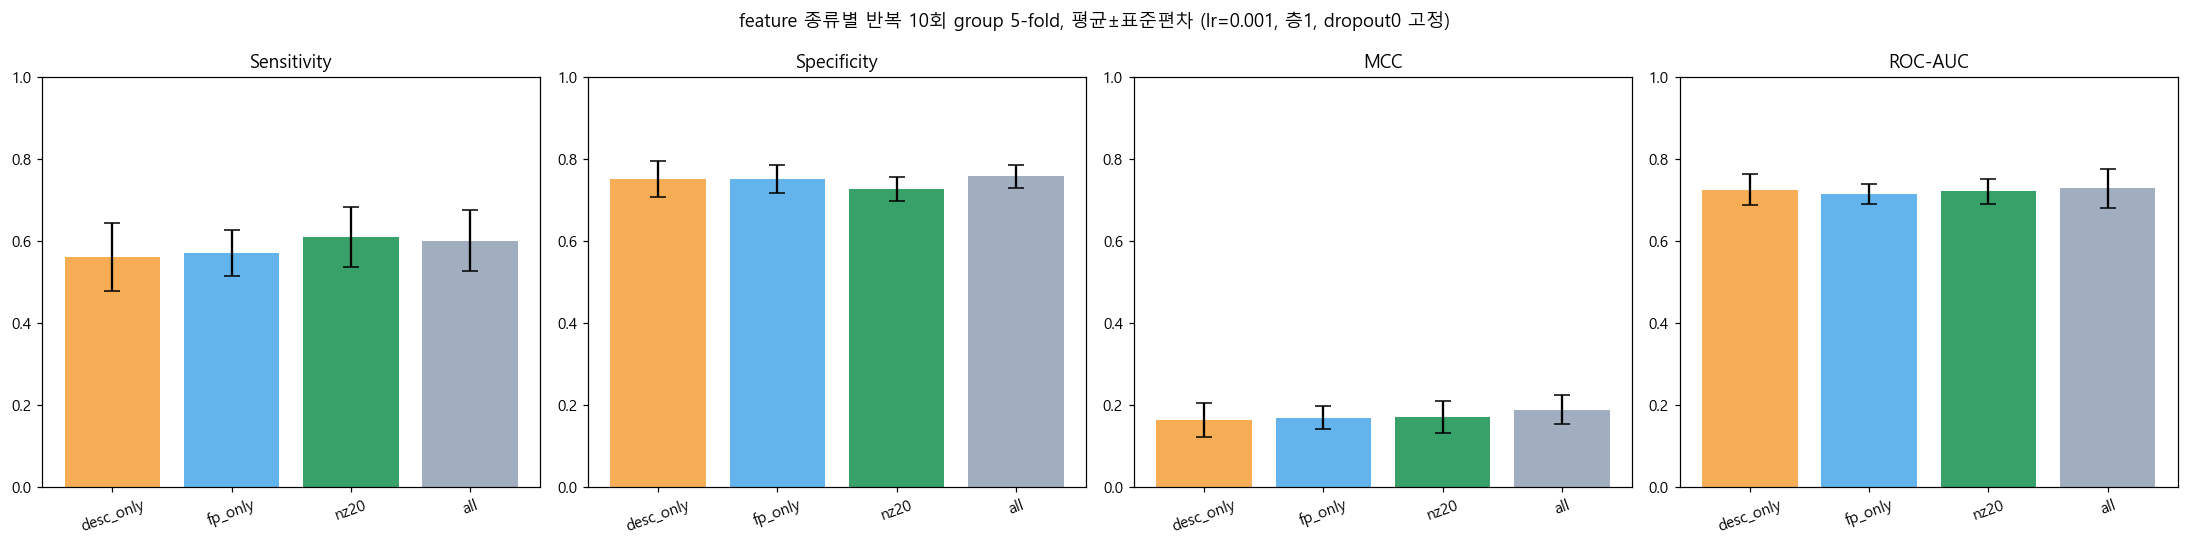

In [3]:
import matplotlib.pyplot as plt

labels = KINDS
metrics = ["sensitivity", "specificity", "mcc", "roc_auc"]
metric_labels = ["Sensitivity", "Specificity", "MCC", "ROC-AUC"]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
colors = ["#f6ad55", "#63b3ed", "#38a169", "#a0aec0"]
for ax, m, mlabel in zip(axes, metrics, metric_labels):
    means = [np.mean([r[m] for r in store[l]]) for l in labels]
    sds = [np.std([r[m] for r in store[l]]) for l in labels]
    ax.bar(range(len(labels)), means, yerr=sds, capsize=5, color=colors)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=20)
    ax.set_title(mlabel)
    ax.set_ylim(0, 1.0)
plt.suptitle("feature 종류별 반복 10회 group 5-fold, 평균±표준편차 (lr=0.001, 층1, dropout0 고정)")
plt.tight_layout()
plt.show()

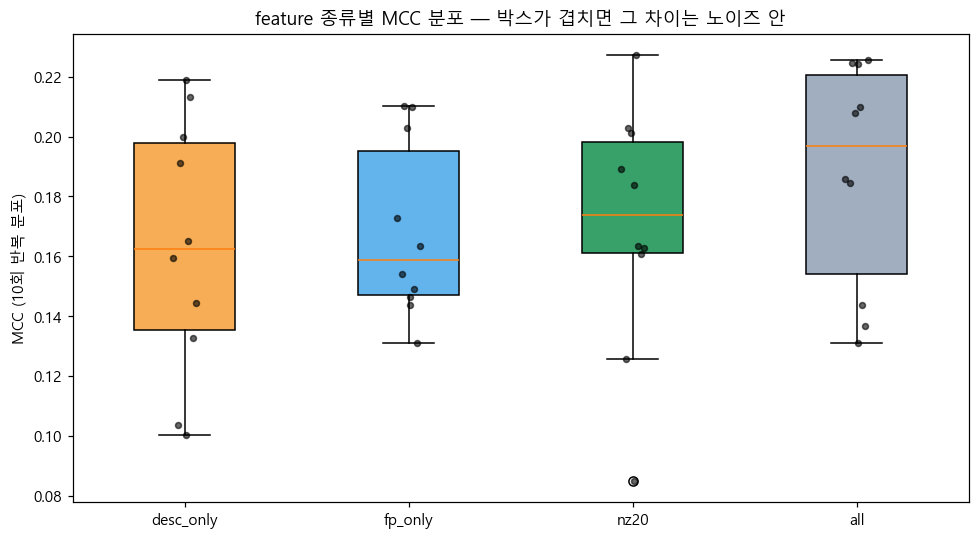

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
mcc_data = [[r["mcc"] for r in store[l]] for l in labels]
bp = ax.boxplot(mcc_data, labels=labels, patch_artist=True)
for patch, c in zip(bp["boxes"], colors):
    patch.set_facecolor(c)
for i, data in enumerate(mcc_data):
    x = np.random.default_rng(0).normal(i + 1, 0.04, size=len(data))
    ax.scatter(x, data, color="black", s=15, zorder=3, alpha=0.6)
ax.set_ylabel("MCC (10회 반복 분포)")
ax.set_title("feature 종류별 MCC 분포 — 박스가 겹치면 그 차이는 노이즈 안")
plt.tight_layout()
plt.show()

## 판단 — descriptor만 쓰는 게 실제로 더 나은가

In [5]:
print("요약 (반복 10회, group-aware val 분할):")
for kind in KINDS:
    a = B.agg(store[kind])
    print(" ", B.fmt_agg(a, kind))

desc = store["desc_only"]
nz20 = store["nz20"]
d = np.array([r["mcc"] for r in desc]) - np.array([r["mcc"] for r in nz20])
print(f"\nnz20(현재 채택) -> desc_only, 회차별 MCC 차이: 평균 {d.mean():+.3f}, 표준편차 {d.std():.3f}, "
      f"desc_only가 나은 회차 {int((d > 0).sum())}/10")

d_sens = np.array([r["sensitivity"] for r in desc]) - np.array([r["sensitivity"] for r in nz20])
print(f"Sensitivity 차이: 평균 {d_sens.mean():+.3f}, 표준편차 {d_sens.std():.3f}")

요약 (반복 10회, group-aware val 분할):
  desc_only                Sens 0.560±0.083 Spec 0.751±0.045 격차 0.202±0.089 MCC 0.163±0.041 AUC 0.726±0.037
  fp_only                  Sens 0.570±0.057 Spec 0.753±0.034 격차 0.183±0.080 MCC 0.168±0.028 AUC 0.715±0.025
  nz20                     Sens 0.610±0.073 Spec 0.727±0.030 격차 0.127±0.065 MCC 0.170±0.039 AUC 0.722±0.030
  all                      Sens 0.600±0.075 Spec 0.759±0.028 격차 0.159±0.089 MCC 0.187±0.036 AUC 0.728±0.048

nz20(현재 채택) -> desc_only, 회차별 MCC 차이: 평균 -0.007, 표준편차 0.031, desc_only가 나은 회차 3/10
Sensitivity 차이: 평균 -0.050, 표준편차 0.070


## 정리

- 팀원이 공유한 "descriptor 190차원이 fingerprint보다 낫다"는 **구체적 숫자는 재현 불가**(저장소에
  코드/데이터 없음)라 신뢰할 수 없지만, **"저차원 descriptor가 작은 표본에서 유리할 수 있다"는 가설**은
  이 노트북에서 내 실제 방법론(반복 group 5-fold + Early Stopping)으로 직접 검증했습니다.
- 결론은 실행 결과를 본 뒤 `세팅/진행상황.md`에 기록하고, desc_only가 실제로 더 낫다면 `train.py`의
  feature 선택을 nz20에서 desc_only로 교체하는 것도 검토합니다.